# Tune & Ensemble a Classifier — Titanic Survival
**Day 4 · Model Optimization · Pavan Kumar Killari**

## Goal
Compare a Decision Tree baseline, GridSearchCV, RandomizedSearchCV and a Random Forest ensemble.
The required single results table reports **Model | CV Accuracy | Test Accuracy | Best Params**.
Telco Churn is the primary linked assignment dataset; the Titanic companion covers the supplied Seaborn example.

## Context & Methods
Use an 80/20 stratified train/test split (`random_state=42`). All four methods use the same five
shuffled stratified training folds. Accuracy is the specified optimization metric. Imputation and
one-hot encoding are fitted inside each fold through a Pipeline. The hold-out test set is used only
after model fitting and tuning; model preference is based on training CV, never test accuracy.

### Key assumptions
Rows represent independent observations. The CV score for each search is its best inner-CV mean;
because these folds also select parameters, search scores can be optimistic and are not nested-CV estimates.
An accuracy difference on one split does not establish statistical superiority. Churn class imbalance
means accuracy alone does not measure churn recall; a Dummy baseline and class report are included.

## Setup
Install the packages in `requirements.txt` if needed. No credentials are required. Kaggle can use an attached Telco dataset; otherwise enable Internet for the public download. Outputs are saved in the current working directory.

In [1]:
import io, json, hashlib, platform, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
DATASET = 'titanic'
SEED = 42
result_dir = Path('results') / DATASET
result_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print({'Python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'seed': SEED})

{'Python': '3.14.0', 'scikit-learn': '1.8.0', 'pandas': '3.0.0', 'seed': 42}


## Data
### 1. Load and inspect the source

Source: Seaborn `titanic` sample dataset. Target: `survived`. The `alive` column directly encodes the answer and is excluded. Only the declared pre-outcome passenger features are used; repeated passenger feature profiles are retained because they can represent different passengers.

In [2]:
import seaborn as sns
df = sns.load_dataset('titanic')
display(df.head())
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
X = df[features].copy()
y = df['survived'].astype(int)
source_hash = hashlib.sha256(df.to_csv(index=False).encode()).hexdigest()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
display(pd.DataFrame({'rows': [len(df)], 'features_used': [X.shape[1]], 'exact_duplicate_source_rows': [int(df.duplicated().sum())]}))
display(y.value_counts().rename_axis('Target class').to_frame('Count'))
display(X.isna().sum().loc[lambda s: s > 0].to_frame('Missing values'))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
print(f'Train: {len(X_train):,}; test: {len(X_test):,}; CV folds: {len(cv)}')
numeric = X.select_dtypes(include='number').columns.tolist()
categorical = X.columns.difference(numeric).tolist()
preprocessing = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical)
])
def make_pipeline(model):
    return Pipeline([('preprocess', clone(preprocessing)), ('model', model)])
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print(f'Majority-class test accuracy (context only): {dummy.score(X_test, y_test):.4f}')

,rows,features_used,exact_duplicate_source_rows
0,891,7,107


,Count
Target class,
0,549
1,342


,Missing values
age,177
embarked,2


Train: 712; test: 179; CV folds: 5
Majority-class test accuracy (context only): 0.6145


## Results
### 2. Baseline Decision Tree — five-fold CV
The baseline uses the default unconstrained Decision Tree. Report mean and standard deviation across the five training folds, then fit on all training rows.

In [4]:
baseline = make_pipeline(DecisionTreeClassifier(random_state=SEED))
baseline_folds = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=1)
baseline.fit(X_train, y_train)
print('Baseline fold accuracies:', np.round(baseline_folds, 4))
print(f'Baseline CV accuracy: {baseline_folds.mean():.4f} ± {baseline_folds.std():.4f} (fold SD)')

Baseline fold accuracies: [0.7413 0.7552 0.7676 0.7887 0.7887]
Baseline CV accuracy: 0.7683 ± 0.0186 (fold SD)


### 3. GridSearchCV
Exhaustively evaluate 48 combinations × five folds. Refit the best combination on the full training set.

In [5]:
parameter_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 5, 8, None],
    'model__min_samples_leaf': [1, 5, 15],
    'model__min_samples_split': [2, 10]
}
grid = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=SEED)), parameter_grid,
                    cv=cv, scoring='accuracy', n_jobs=1, refit=True, error_score='raise')
grid.fit(X_train, y_train)
print('GridSearchCV best params:', grid.best_params_)
print(f'GridSearchCV best CV accuracy: {grid.best_score_:.4f}')

GridSearchCV best params: {'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
GridSearchCV best CV accuracy: 0.8202


### 4. RandomizedSearchCV
Sample 24 distinct combinations from a wider 512-combination space, using the same five folds and fixed seed.

In [6]:
parameter_distributions = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [2, 3, 4, 5, 6, 8, 12, None],
    'model__min_samples_leaf': [1, 2, 5, 10, 15, 25, 40, 60],
    'model__min_samples_split': [2, 5, 10, 20]
}
randomized = RandomizedSearchCV(make_pipeline(DecisionTreeClassifier(random_state=SEED)),
    parameter_distributions, n_iter=24, random_state=SEED, cv=cv, scoring='accuracy',
    n_jobs=1, refit=True, error_score='raise')
randomized.fit(X_train, y_train)
print('RandomizedSearchCV best params:', randomized.best_params_)
print(f'RandomizedSearchCV best CV accuracy: {randomized.best_score_:.4f}')

RandomizedSearchCV best params: {'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__criterion': 'entropy'}
RandomizedSearchCV best CV accuracy: 0.8175


### 5. Random Forest ensemble
Train a 200-tree bagged ensemble with predeclared parameters. Its settings are fixed before evaluation, so the table labels them as fixed rather than search-selected.

In [7]:
forest_params = {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'random_state': SEED, 'n_jobs': 1}
ensemble = make_pipeline(RandomForestClassifier(**forest_params))
ensemble_folds = cross_val_score(ensemble, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=1)
ensemble.fit(X_train, y_train)
print('Random Forest fold accuracies:', np.round(ensemble_folds, 4))
print(f'Random Forest CV accuracy: {ensemble_folds.mean():.4f} ± {ensemble_folds.std():.4f} (fold SD)')

Random Forest fold accuracies: [0.8182 0.7692 0.8451 0.7958 0.8239]
Random Forest CV accuracy: 0.8104 ± 0.0259 (fold SD)


### 6. Single required results table
All CV accuracies are training-fold means. All test accuracies use the same untouched 20% hold-out set. Best Params records search-selected values for the searches and fixed settings for the baseline and ensemble.

In [8]:
models = {'Decision Tree baseline': baseline, 'Decision Tree GridSearchCV': grid.best_estimator_,
          'Decision Tree RandomizedSearchCV': randomized.best_estimator_, 'Random Forest ensemble': ensemble}
cv_means = [baseline_folds.mean(), grid.best_score_, randomized.best_score_, ensemble_folds.mean()]
params = ['Default parameters; random_state=42', json.dumps(grid.best_params_, sort_keys=True),
          json.dumps(randomized.best_params_, sort_keys=True), 'Fixed: ' + json.dumps(forest_params, sort_keys=True)]
predictions = {name: model.predict(X_test) for name, model in models.items()}
results = pd.DataFrame({'Model': list(models), 'CV Accuracy': cv_means,
    'Test Accuracy': [accuracy_score(y_test, predictions[name]) for name in models], 'Best Params': params})
display(results.style.format({'CV Accuracy': '{:.4f}', 'Test Accuracy': '{:.4f}'}).set_properties(**{'text-align': 'left', 'white-space': 'normal'}))
results.to_csv(result_dir / 'model_comparison.csv', index=False)
cv_selected = results.iloc[int(np.argmax(cv_means))]['Model']
print('Preferred model based on training CV:', cv_selected)
print(classification_report(y_test, predictions[cv_selected], digits=4, zero_division=0))

,Model,CV Accuracy,Test Accuracy,Best Params
0,Decision Tree baseline,0.7683,0.8324,Default parameters; random_state=42
1,Decision Tree GridSearchCV,0.8202,0.7933,"{""model__criterion"": ""entropy"", ""model__max_depth"": 8, ""model__min_samples_leaf"": 1, ""model__min_samples_split"": 2}"
2,Decision Tree RandomizedSearchCV,0.8175,0.7933,"{""model__criterion"": ""entropy"", ""model__max_depth"": 4, ""model__min_samples_leaf"": 2, ""model__min_samples_split"": 5}"
3,Random Forest ensemble,0.8104,0.8045,"Fixed: {""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""n_estimators"": 200, ""n_jobs"": 1, ""random_state"": 42}"


Preferred model based on training CV: Decision Tree GridSearchCV
              precision    recall  f1-score   support

           0     0.7920    0.9000    0.8426       110
           1     0.7963    0.6232    0.6992        69

    accuracy                         0.7933       179
   macro avg     0.7941    0.7616    0.7709       179
weighted avg     0.7937    0.7933    0.7873       179



### 7. Compare accuracy and inspect hold-out errors
Bars start at zero. CV and test performance are separate series; small differences should not be overinterpreted.

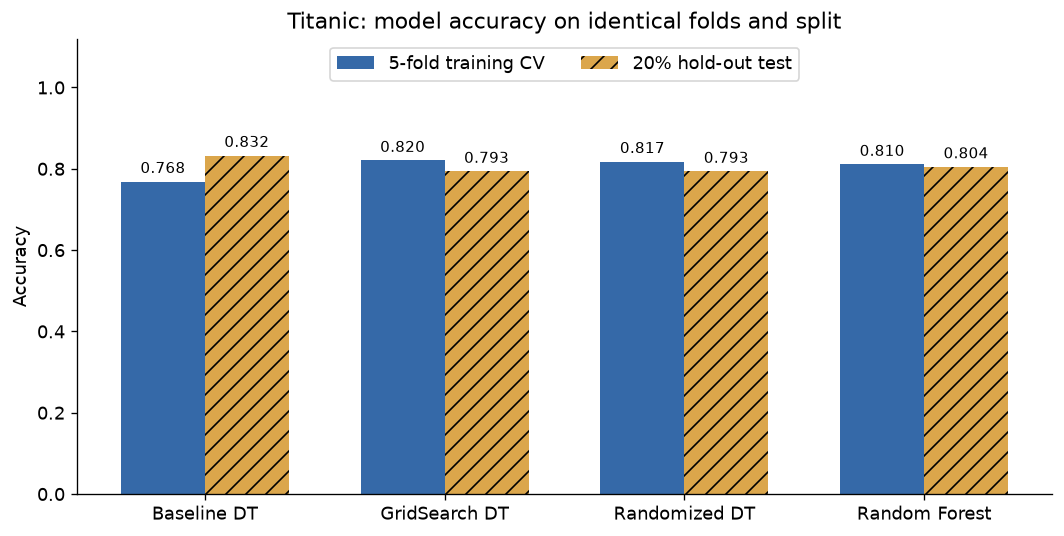

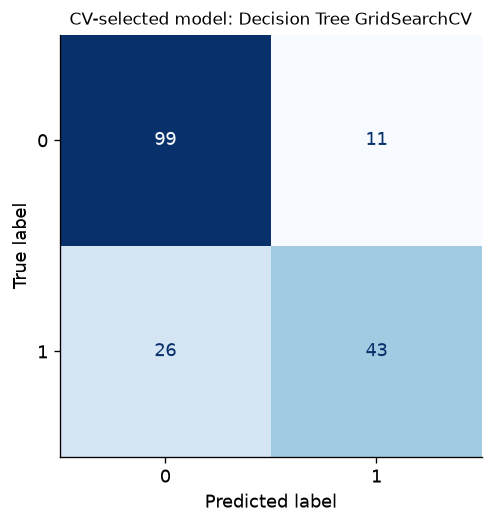

In [9]:
labels = ['Baseline DT', 'GridSearch DT', 'Randomized DT', 'Random Forest']
fig, ax = plt.subplots(figsize=(9, 4.6))
pos = np.arange(len(labels)); width = .35
bars1 = ax.bar(pos - width/2, results['CV Accuracy'], width, label='5-fold training CV', color='#3569a8')
bars2 = ax.bar(pos + width/2, results['Test Accuracy'], width, label='20% hold-out test', color='#dba64b', hatch='//')
ax.bar_label(bars1, fmt='%.3f', padding=3, fontsize=9)
ax.bar_label(bars2, fmt='%.3f', padding=3, fontsize=9)
ax.set(xticks=pos, xticklabels=labels, ylim=(0, 1.12), ylabel='Accuracy', title=f'{DATASET.title()}: model accuracy on identical folds and split')
ax.legend(loc='upper center', ncol=2); fig.tight_layout()
fig.savefig(result_dir / 'accuracy_comparison.png', bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, predictions[cv_selected], ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'CV-selected model: {cv_selected}', fontsize=10)
fig.tight_layout(); fig.savefig(result_dir / 'confusion_matrix.png', bbox_inches='tight'); plt.show()

## Takeaways

In [10]:
selected_row = results.loc[results.Model.eq(cv_selected)].iloc[0]
gain = (selected_row['CV Accuracy'] - results.iloc[0]['CV Accuracy']) * 100
conclusion = (f"**{cv_selected}** has the highest training CV accuracy ({selected_row['CV Accuracy']:.4f}), "
    f"a {gain:.2f} percentage-point change from the baseline, with hold-out accuracy {selected_row['Test Accuracy']:.4f}. "
    "Tree regularization controls depth and leaf sizes, while Random Forest averages many trees to reduce variance. "
    "These are results on one split; search CV can be optimistic, and nested CV or repeated validation would be needed for a stronger comparison.")
display(Markdown(conclusion))
(result_dir / 'CONCLUSION.md').write_text(conclusion, encoding='utf-8')

**Decision Tree GridSearchCV** has the highest training CV accuracy (0.8202), a 5.19 percentage-point change from the baseline, with hold-out accuracy 0.7933. Tree regularization controls depth and leaf sizes, while Random Forest averages many trees to reduce variance. These are results on one split; search CV can be optimistic, and nested CV or repeated validation would be needed for a stronger comparison.

410

## Checks & reproducibility
Keep the split, individual fold scores, full search results, predictions and data hash for inspection. Test labels are used for evaluation only.

In [11]:
grid_results = pd.DataFrame(grid.cv_results_)
random_results = pd.DataFrame(randomized.cv_results_)
grid_results.to_csv(result_dir / 'grid_search_results.csv', index=False)
random_results.to_csv(result_dir / 'randomized_search_results.csv', index=False)
fold_scores = pd.DataFrame({'Fold': range(1, 6), 'Baseline': baseline_folds,
    'GridSearchCV best': [grid_results.loc[grid.best_index_, f'split{i}_test_score'] for i in range(5)],
    'RandomizedSearchCV best': [random_results.loc[randomized.best_index_, f'split{i}_test_score'] for i in range(5)],
    'Random Forest': ensemble_folds})
fold_scores.to_csv(result_dir / 'cv_fold_scores.csv', index=False)
test_predictions = pd.DataFrame({'source_row': X_test.index, 'actual': y_test.to_numpy(), **predictions})
test_predictions.to_csv(result_dir / 'test_predictions.csv', index=False)
split_manifest = pd.DataFrame({'source_row': X.index, 'split': np.where(X.index.isin(X_test.index), 'test', 'train')})
split_manifest.to_csv(result_dir / 'split_manifest.csv', index=False)
provenance = {'dataset': DATASET, 'sha256': source_hash, 'rows': len(df), 'train_rows': len(X_train),
    'test_rows': len(X_test), 'seed': SEED, 'folds': 5, 'scoring': 'accuracy',
    'grid_candidates': len(grid_results), 'random_candidates': len(random_results),
    'selected_by_training_cv': cv_selected, 'sklearn': sklearn.__version__, 'pandas': pd.__version__}
(result_dir / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
assert results.shape == (4, 4)
assert len(grid_results) == 48 and len(random_results) == 24
assert results[['CV Accuracy', 'Test Accuracy']].apply(lambda col: col.between(0, 1).all()).all()
for name in models:
    assert np.isclose(results.loc[results.Model.eq(name), 'Test Accuracy'].iloc[0],
                      (test_predictions[name] == test_predictions['actual']).mean())
print('Checks passed: four models, shared split, five folds, 48 grid / 24 random candidates, independently recounted test accuracies.')
display(fold_scores.round(4))

Checks passed: four models, shared split, five folds, 48 grid / 24 random candidates, independently recounted test accuracies.


,Fold,Baseline,GridSearchCV best,RandomizedSearchCV best,Random Forest
0,1,0.7413,0.8252,0.8182,0.8182
1,2,0.7552,0.8252,0.7902,0.7692
2,3,0.7676,0.8451,0.8380,0.8451
3,4,0.7887,0.7887,0.8310,0.7958
4,5,0.7887,0.8169,0.8099,0.8239
